# 03 — Denoising Diffusion Probabilistic Model (DDPM)

**Forward process** (tetap, tanpa parameter): $q(x_t\mid x_0)=\mathcal{N}(\sqrt{\bar\alpha_t}\,x_0,\ (1-\bar\alpha_t)I)$,
dengan $\beta_t$ linear dari $10^{-4}$ ke $0.02$ dan $T=1000$.

**Objektif sederhana** (Ho et al., 2020) berupa regresi terawasi pada derau:
$$\mathcal{L}_{simple}=\mathbb{E}_{t,x_0,\epsilon}\big\lVert\epsilon-\epsilon_\theta(\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\ t)\big\rVert^2$$

**Reverse process** (ancestral sampling):
$x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\Big(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t,t)\Big)+\sqrt{\beta_t}\,z$

Jaringan $\epsilon_\theta$ adalah U-Net kecil (resolusi 28 → 14 → 7, kanal 32/64/128, self-attention di bottleneck,
time embedding sinusoidal). Model dilatih 30 epoch, memakai AMP (fp16) dan EMA bobot (decay 0.999).

In [1]:
# ===== Import library =====
import time                           # mengukur waktu sampling
import torch
import matplotlib.pyplot as plt
from collections import defaultdict

from common import *
# UNet = jaringan penebak noise, DDPM = proses difusi, EMA = rata-rata bergerak bobot
from models import UNet, DDPM, EMA

set_seed(SEED)
# cudnn.benchmark sengaja TIDAK diaktifkan: pada cuDNN 9 benchmark memicu kompilasi JIT engine fusi
# yang memerlukan banyak RAM host (penyebab "Memory allocation failure" pada laptop 12 GB).
train_loader, val_loader, test_loader = get_loaders(BATCH_SIZE)

# ===== Hyperparameter =====
EPOCHS = 1 if QUICK else 30
N_SAMPLES = 200 if QUICK else 2000      # jumlah sampel untuk FID (sama untuk semua model)
LR = 2e-4
# Konfigurasi U-Net: 32 channel dasar, dikali (1,2,4) di tiap level resolusi, 1 ResBlock per level
UNET_CFG = dict(ch=32, ch_mult=(1, 2, 4), num_res=1, dropout=0.1)

unet = UNet(**UNET_CFG).to(DEVICE)          # jaringan epsilon_theta(x_t, t)
ddpm = DDPM(unet, T=1000).to(DEVICE)         # proses difusi 1000 langkah
ema = EMA(unet, decay=0.999)                 # salinan bobot rata-rata (dipakai saat sampling)
opt = torch.optim.Adam(unet.parameters(), lr=LR)
# GradScaler: menskalakan loss saat training fp16 (AMP) agar gradien kecil tidak menjadi nol
scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
print("U-Net params:", count_params(unet))

U-Net params: 2536033


## Training (prediksi derau)
Validation loss dihitung dengan $t$ dan $\epsilon$ yang di-seed tetap agar kurva antar-epoch dapat dibandingkan.

In [2]:
@torch.no_grad()
def val_loss(model_ddpm):
    model_ddpm.model.eval()
    # t dan noise diambil dengan seed tetap -> nilai val loss antar-epoch bisa dibandingkan
    gen = torch.Generator(device=DEVICE).manual_seed(SEED)
    tot, n = 0.0, 0
    for x, _ in val_loader:
        x0 = to_tanh_range(x.to(DEVICE))   # piksel ke [-1, 1]
        t = torch.randint(0, model_ddpm.T, (x0.size(0),), device=DEVICE, generator=gen)   # timestep acak
        noise = torch.randn(x0.shape, device=DEVICE, generator=gen)                       # noise acak
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16):
            # Tambahkan noise ke x0 -> x_t, lalu minta U-Net menebak noise-nya
            pred = model_ddpm.model(model_ddpm.q_sample(x0, t, noise), t)
        tot += torch.nn.functional.mse_loss(pred.float(), noise).item()   # MSE tebakan vs noise asli
        n += 1
    return tot / n


# Checkpoint per epoch: training dapat dilanjutkan (resume) bila proses terhenti di tengah jalan.
RESUME_PATH = os.path.join(CKPT_DIR, "ddpm_resume.pt")
hist, start_ep = defaultdict(list), 1
if os.path.exists(RESUME_PATH) and not QUICK:
    # Muat kembali semua state: bobot, EMA, optimizer, scaler, dan state generator acak
    ck = torch.load(RESUME_PATH, map_location=DEVICE, weights_only=False)
    unet.load_state_dict(ck["unet"]); ema.shadow.load_state_dict(ck["ema"])
    opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
    torch.set_rng_state(ck["rng_cpu"]); torch.cuda.set_rng_state(ck["rng_cuda"])
    train_loader.generator.set_state(ck["rng_loader"])
    hist.update(ck["hist"]); start_ep = ck["epoch"] + 1   # lanjut dari epoch berikutnya
    print(f"melanjutkan dari epoch {start_ep}")

for ep in range(start_ep, EPOCHS + 1):
    unet.train()
    losses = []
    with EpochTimer() as tm:
        for x, _ in train_loader:
            x0 = to_tanh_range(x.to(DEVICE))
            # AMP: forward dalam fp16 agar lebih cepat & hemat memori GPU
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16):
                loss = ddpm.loss(x0)            # pilih t acak, tambah noise, tebak noise, hitung MSE
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()       # backprop dengan loss yang diskalakan
            scaler.step(opt)                    # update bobot (gradien di-unscale dulu)
            scaler.update()                     # sesuaikan faktor skala untuk iterasi berikutnya
            ema.update(unet)                    # perbarui bobot rata-rata EMA
            losses.append(loss.detach())
    # Simpan statistik epoch
    losses = torch.stack(losses).float().cpu()
    hist["iter_loss"].extend(losses.tolist())
    hist["epoch_time"].append(tm.seconds)
    hist["train_loss"].append(losses.mean().item())
    # Validasi memakai bobot EMA (yang nanti dipakai untuk sampling)
    hist["val_loss"].append(val_loss(DDPM(ema.shadow, T=1000).to(DEVICE)))
    print(f"[ddpm] epoch {ep:02d} | train {hist['train_loss'][-1]:.4f} | val(EMA) {hist['val_loss'][-1]:.4f} "
          f"| {tm.seconds:.1f}s")
    # Simpan checkpoint resume tiap epoch
    if not QUICK:
        torch.save({"unet": unet.state_dict(), "ema": ema.shadow.state_dict(), "opt": opt.state_dict(),
                    "scaler": scaler.state_dict(), "rng_cpu": torch.get_rng_state(),
                    "rng_cuda": torch.cuda.get_rng_state(), "rng_loader": train_loader.generator.get_state(),
                    "hist": dict(hist), "epoch": ep}, RESUME_PATH)

# Simpan bobot akhir (biasa & EMA) dan riwayat training
torch.save(unet.state_dict(), os.path.join(CKPT_DIR, "ddpm_unet.pt"))
torch.save(ema.shadow.state_dict(), os.path.join(CKPT_DIR, "ddpm_unet_ema.pt"))
save_json(dict(hist), "history_ddpm.json")

[ddpm] epoch 01 | train 0.1076 | val(EMA) 0.2954 | 66.9s


[ddpm] epoch 02 | train 0.0608 | val(EMA) 0.1103 | 60.9s


[ddpm] epoch 03 | train 0.0533 | val(EMA) 0.0771 | 49.2s


[ddpm] epoch 04 | train 0.0494 | val(EMA) 0.0632 | 49.2s


[ddpm] epoch 05 | train 0.0482 | val(EMA) 0.0539 | 53.7s


[ddpm] epoch 06 | train 0.0465 | val(EMA) 0.0479 | 61.3s


... (20 outputs left out)

[ddpm] epoch 27 | train 0.0387 | val(EMA) 0.0360 | 67.5s


[ddpm] epoch 28 | train 0.0390 | val(EMA) 0.0359 | 52.6s


[ddpm] epoch 29 | train 0.0377 | val(EMA) 0.0358 | 49.1s


[ddpm] epoch 30 | train 0.0389 | val(EMA) 0.0358 | 49.4s


## Sampling: trajektori reverse diffusion $x_T \rightarrow x_0$

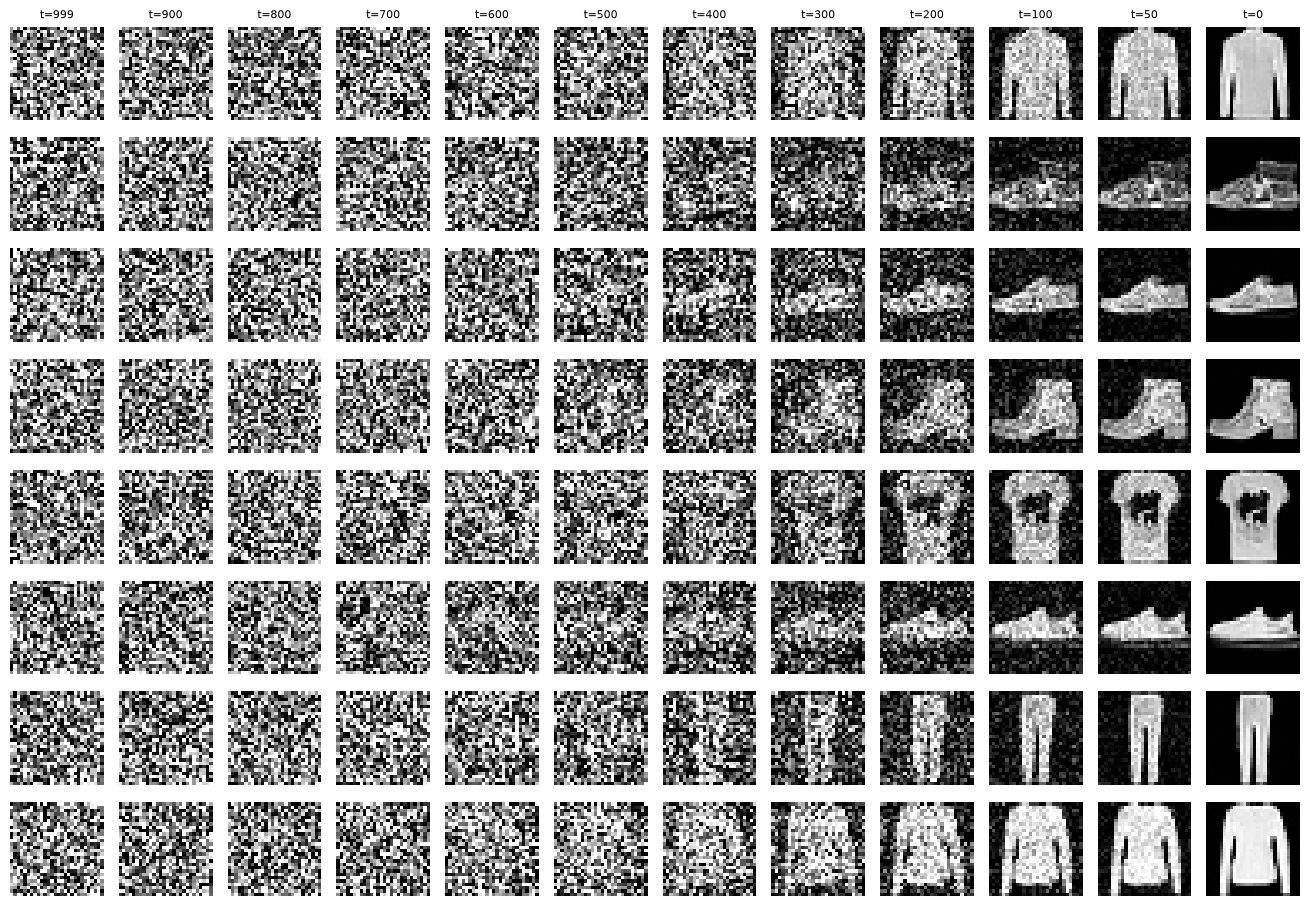

In [3]:
# DDPM dengan bobot EMA untuk sampling (hasil biasanya lebih halus)
ddpm_ema = DDPM(ema.shadow, T=1000).to(DEVICE).eval()
# Timestep yang ingin direkam: dari noise murni (999) sampai gambar jadi (0)
TRAJ_T = [999, 900, 800, 700, 600, 500, 400, 300, 200, 100, 50, 0]
set_seed(SEED)
# Buat 8 sampel sambil merekam gambar antara pada timestep di TRAJ_T
x0_traj, traj = ddpm_ema.sample(8, DEVICE, return_traj_at=set(TRAJ_T), amp=True)
# Simpan trajektori (dalam rentang [0,1]) untuk dipakai di notebook 05
torch.save({"t": TRAJ_T, "traj": {t: from_tanh_range(traj[t]) for t in TRAJ_T}},
           os.path.join(RESULTS_DIR, "ddpm_trajectory.pt"))

# Grid 8 baris (sampel) x 12 kolom (timestep): terlihat noise perlahan berubah menjadi pakaian
fig, axes = plt.subplots(8, len(TRAJ_T), figsize=(len(TRAJ_T) * 1.1, 8 * 1.15))
for j, t in enumerate(TRAJ_T):
    for i in range(8):
        axes[i, j].imshow(from_tanh_range(traj[t][i, 0]), cmap="gray", vmin=0, vmax=1)
        axes[i, j].axis("off")
    axes[0, j].set_title(f"t={t}", fontsize=8)
plt.tight_layout()
plt.show()

## Sampel untuk evaluasi FID
Sampel disimpan sebagai uint8 agar notebook evaluasi (05) tidak perlu mengulang 1000 langkah sampling.

2000 sampel dalam 562.1s


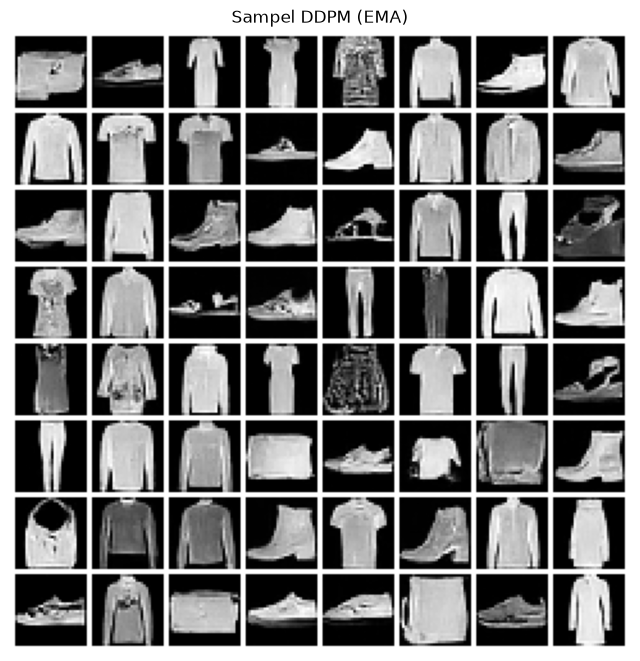

In [4]:
set_seed(SEED)
chunks = []
sync(); t0 = time.perf_counter()   # mulai ukur waktu sampling
# Buat N_SAMPLES gambar dalam potongan 500 agar memori GPU cukup
for i in range(0, N_SAMPLES, 500):
    chunks.append(from_tanh_range(ddpm_ema.sample(min(500, N_SAMPLES - i), DEVICE, amp=True)).cpu())
sync(); sample_time = time.perf_counter() - t0
samples = torch.cat(chunks)
# Simpan sebagai uint8 (0-255) agar file kecil; dipakai untuk FID di notebook 05
torch.save((samples * 255).round().to(torch.uint8), os.path.join(RESULTS_DIR, "samples_ddpm.pt"))
# Simpan info sampling (waktu, konfigurasi U-Net, jumlah parameter)
save_json({"n_samples": N_SAMPLES, "total_sampling_seconds": sample_time,
           "seconds_per_image": sample_time / N_SAMPLES, "unet_cfg": UNET_CFG,
           "params": count_params(unet)}, "ddpm_sampling_info.json")
print(f"{N_SAMPLES} sampel dalam {sample_time:.1f}s")
# Tampilkan 64 sampel pertama
show_grid(samples[:64], nrow=8, title="Sampel DDPM (EMA)")
plt.show()